# Projet de synthèse M201 — MarocShop
Auteur : Ziyad Damghi

# Partie 1 — Découverte, types de variables et nettoyage

In [131]:
import pandas as pd
import numpy as np
import statistics
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

In [132]:
df_org  = pd.read_csv(r"/home/ziyad/Desktop/IA_DATA_2026_2027/02_ISMO_COURS_ET_TP/Principale/Module_1_Math/projet_final/Analyse-des-commandes-et-des-messages-clients-de-MarocShop/data/commandes.csv")

In [133]:
df = df_org.copy()

In [134]:
df.shape

(518, 14)

In [135]:
cat_col = ["ville", "sexe", "categorie", "canal", "entrepot","colis_endommage", "satisfaction", "retour_client"]

for c in cat_col:
    df[c] = df[c].str.strip().str.lower().str.replace('è' , 'e').str.replace('é' , 'e')

In [136]:
for i in cat_col:
    print(df[i].value_counts(), "\n")

ville
casablanca    126
rabat          87
tanger         79
marrakech      74
fes            57
agadir         48
tetouan        47
Name: count, dtype: int64 

sexe
femme    266
homme    242
Name: count, dtype: int64 

categorie
mode            142
electronique    108
maison           99
beaute           92
sport            77
Name: count, dtype: int64 

canal
web            252
application    194
telephone       64
Name: count, dtype: int64 

entrepot
a    255
b    171
c     92
Name: count, dtype: int64 

colis_endommage
non    487
oui     31
Name: count, dtype: int64 

satisfaction
moyen     230
eleve     175
faible     70
Name: count, dtype: int64 

retour_client
non    431
oui     87
Name: count, dtype: int64 



In [137]:
print(df.isna().sum(), "\n")

id_commande               0
date_commande             0
ville                     0
sexe                     10
age_client               23
categorie                 0
canal                     8
nb_articles               6
montant_dh               15
entrepot                  0
delai_livraison_jours    18
colis_endommage           0
satisfaction             43
retour_client             0
dtype: int64 



In [138]:
df.head()

,id_commande,date_commande,ville,sexe,age_client,categorie,canal,nb_articles,montant_dh,entrepot,delai_livraison_jours,colis_endommage,satisfaction,retour_client
0,CMD0001,2025-01-01,casablanca,femme,44.0,beaute,application,3.0,210.97,a,2.0,non,moyen,non
1,CMD0002,2025-01-01,tetouan,femme,26.0,mode,web,5.0,579.45,b,5.0,non,faible,non
2,CMD0003,2025-01-03,tanger,homme,28.0,sport,application,2.0,372.35,b,2.0,non,eleve,non
3,CMD0004,2025-01-05,rabat,femme,18.0,mode,application,3.0,478.11,c,4.0,oui,faible,oui
4,CMD0005,2025-01-05,rabat,femme,41.0,electronique,application,7.0,411.04,c,4.0,non,eleve,non


In [139]:
df.dtypes

id_commande                  str
date_commande                str
ville                        str
sexe                         str
age_client               float64
categorie                    str
canal                        str
nb_articles              float64
montant_dh               float64
entrepot                     str
delai_livraison_jours    float64
colis_endommage              str
satisfaction                 str
retour_client                str
dtype: object

In [140]:
print(f' les nombre des doublans {df.duplicated().sum()}')

 les nombre des doublans 18


In [141]:
valeurs_num = df.select_dtypes(include= "number")
valeurs_cat = df.select_dtypes(include= "str")
for i in valeurs_num :
    manquante_num = ((valeurs_num[i].isnull().mean())*100).round(1)
    print(i ,":" , manquante_num , "%")
for j in valeurs_cat:
    manquante_cat = ((valeurs_cat[j].isnull().mean())*100).round(1)
    
    print(j ,":"  ,manquante_cat , "%")

age_client : 4.4 %
nb_articles : 1.2 %
montant_dh : 2.9 %
delai_livraison_jours : 3.5 %
id_commande : 0.0 %
date_commande : 0.0 %
ville : 0.0 %
sexe : 1.9 %
categorie : 0.0 %
canal : 1.5 %
entrepot : 0.0 %
colis_endommage : 0.0 %
satisfaction : 8.3 %
retour_client : 0.0 %


In [142]:
df.columns.str.strip().str.lower()

Index(['id_commande', 'date_commande', 'ville', 'sexe', 'age_client',
       'categorie', 'canal', 'nb_articles', 'montant_dh', 'entrepot',
       'delai_livraison_jours', 'colis_endommage', 'satisfaction',
       'retour_client'],
      dtype='str')

In [143]:
df['date_commande'] = pd.to_datetime(df['date_commande'] , format= 'mixed')
df['mois'] = df['date_commande'].dt.month


In [144]:
future = df['date_commande'] > pd.Timestamp.today()
future.sum()

np.int64(0)

In [145]:
doublans = df[df.duplicated(keep= False)]
len(doublans)

36

In [146]:
df.duplicated().sum()

np.int64(18)

In [147]:
df = df.drop_duplicates()

In [148]:
df.shape

(500, 15)

In [149]:
df = df.drop_duplicates(subset= 'id_commande')

In [150]:
df.shape

(500, 15)

In [151]:
df.describe()

,date_commande,age_client,nb_articles,montant_dh,delai_livraison_jours,mois
count,500,478.000000,494.000000,485.000000,482.000000,500.000000
mean,2025-07-02 15:07:12,34.941423,2.522267,710.774412,3.537344,6.550000
min,2025-01-01 00:00:00,0.000000,0.000000,-150.000000,-2.000000,1.000000
25%,2025-04-01 18:00:00,27.000000,1.000000,261.170000,2.000000,4.000000
50%,2025-07-04 00:00:00,35.000000,2.000000,385.870000,3.000000,7.000000
75%,2025-09-29 00:00:00,42.000000,3.000000,616.060000,4.000000,9.000000
max,2025-12-30 00:00:00,130.000000,40.000000,32000.000000,60.000000,12.000000
std,NaN,11.686359,2.620428,2227.797358,3.834364,3.422122


In [152]:
df.isnull().sum().sort_values(ascending=False)

satisfaction             40
age_client               22
delai_livraison_jours    18
montant_dh               15
sexe                     10
canal                     8
nb_articles               6
categorie                 0
id_commande               0
date_commande             0
ville                     0
entrepot                  0
colis_endommage           0
retour_client             0
mois                      0
dtype: int64

In [153]:
for c in ["age_client", "nb_articles",  "delai_livraison_jours" , 'montant_dh']:
    df[c] = df[c].fillna(df[c].median())

In [154]:
for c in ["ville", "sexe", "canal", "satisfaction"]:
    df[c] = df[c].fillna(df[c].mode()[0]) 

In [155]:
df.isnull().sum()

id_commande              0
date_commande            0
ville                    0
sexe                     0
age_client               0
categorie                0
canal                    0
nb_articles              0
montant_dh               0
entrepot                 0
delai_livraison_jours    0
colis_endommage          0
satisfaction             0
retour_client            0
mois                     0
dtype: int64

In [156]:
df.to_csv('commandes_nettoye.csv')

# Partie 2 — Mesures centrales
Données utilisées : commandes_nettoye.csv (doublons et manquants traités, outliers conservés)

In [157]:
valeurs_num = df.select_dtypes(include = 'float')
valeurs_cat = df.select_dtypes(include= "str")

In [158]:
for i in valeurs_num:
    MOYENNE = np.mean(valeurs_num[i])
    MEDIANE= np.median(valeurs_num[i])
    MODE= valeurs_num[i].mode()
    print(i, ": moyenne :", MOYENNE, "Median :", MEDIANE, " Mode :", MODE ,'\n') 

age_client : moyenne : 34.944 Median : 35.0  Mode : 0    35.0
Name: age_client, dtype: float64 

nb_articles : moyenne : 2.516 Median : 2.0  Mode : 0    1.0
Name: nb_articles, dtype: float64 

montant_dh : moyenne : 701.02728 Median : 385.87  Mode : 0    385.87
Name: montant_dh, dtype: float64 

delai_livraison_jours : moyenne : 3.518 Median : 3.0  Mode : 0    3.0
Name: delai_livraison_jours, dtype: float64 



In [159]:
for i in ['ville', 'categorie', 'canal' , 'satisfaction'] :
    print(f"le mode de {i} est :{df[i].mode()[0]}")

le mode de ville est :casablanca
le mode de categorie est :mode
le mode de canal est :web
le mode de satisfaction est :moyen


In [160]:
resultat = df.groupby('categorie')['montant_dh'].agg(['mean' , 'median' ])
resultat

,mean,median
categorie,,
beaute,486.666136,193.460
electronique,1119.087549,1041.190
maison,1040.346211,474.430
mode,470.493525,311.700
sport,385.639474,379.575


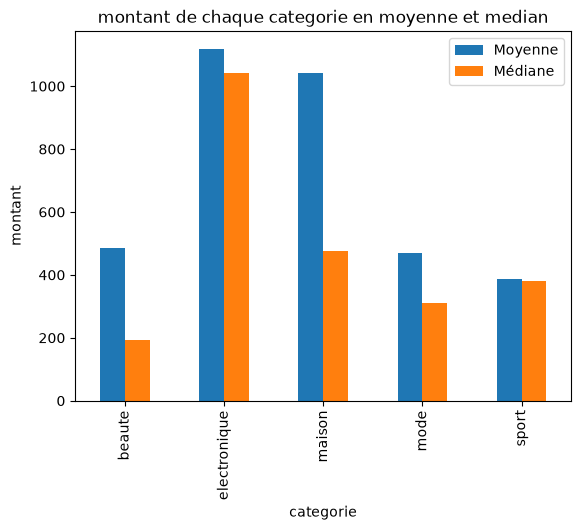

In [161]:
resultat.plot(kind = 'bar')
plt.legend(["Moyenne", "Médiane"])
plt.xlabel('categorie')
plt.ylabel('montant')
plt.title('montant de chaque categorie en moyenne et median')
plt.show()

# Partie 3 — Mesures de dispersion

In [162]:
for i in  ['age_client' , 'montant_dh' , 'delai_livraison_jours']:
    variance = np.var(df[i] ,ddof=1)
    max_i = df[i].max()
    min_i = df[i].min()
    etendu = max_i - min_i
    ecart_type = np.std(df[i] , ddof = 1)
    print(i, ": variance :", variance, "etendu :", etendu, " ecart type :", ecart_type ,'\n')

age_client : variance : 130.5499639278557 etendu : 130.0  ecart type : 11.425846311230329 

montant_dh : variance : 4816968.289223449 etendu : 32150.0  ecart type : 2194.759278195094 

delai_livraison_jours : variance : 14.182040080160322 etendu : 62.0  ecart type : 3.7659049483703546 



In [163]:
df.groupby('ville')['delai_livraison_jours'].agg(['count','std' , 'mean' , 'median', 'max']).sort_values(by = 'std' , ascending= True)

,count,std,mean,median,max
ville,,,,,
marrakech,71,1.141146,3.591549,4.0,7.0
tetouan,46,1.196614,3.652174,4.0,6.0
fes,55,1.212449,3.581818,3.0,6.0
agadir,47,1.268344,5.000000,5.0,7.0
rabat,84,3.963021,3.297619,3.0,38.0
casablanca,121,4.008565,2.487603,2.0,45.0
tanger,76,6.586483,4.289474,3.0,60.0


In [164]:
df_drop = df.nlargest(5, 'montant_dh')


In [165]:
df4 = df.drop(df_drop.index)

In [166]:
for i in  ['montant_dh' ]:
    variance = np.var(df[i] ,ddof=1)
    max_i = df[i].max()
    min_i = df[i].min()
    etendu = max_i - min_i
    ecart_type = np.std(df[i] , ddof = 1)
    print(i, ": variance :", variance, "etendu :", etendu, " ecart type :", ecart_type ,'\n')

montant_dh : variance : 4816968.289223449 etendu : 32150.0  ecart type : 2194.759278195094 



# Partie 4 — Mesures de position et premiers outliers

In [167]:
Q = [0.25 , 0.50 , 0.75]
D =   [10 , 50 , 90]
C = [95, 99]
resultat_q = []
resultat_d =[] 
resultat_c = []
for i in [Q]:
   q = np.quantile(df['montant_dh'] , i)
   resultat_q.append({'Type' : 'Quantile' , 'niveau' : i , 'valeur' : q})
for i in [D]:
   q = np.percentile(df['montant_dh'] , i)
   resultat_d.append({'Type' : 'Deciles' , 'niveau' : i , 'valeur' : q})
for i in [C]:
   q = np.percentile(df['montant_dh'] , i)
   resultat_c.append({'Type' : 'Centile' , 'niveau' : i , 'valeur' : q})  
print(resultat_q , '\n' , resultat_d , '\n' , resultat_c )


[{'Type': 'Quantile', 'niveau': [0.25, 0.5, 0.75], 'valeur': array([266.0425, 385.87  , 609.7475])}] 
 [{'Type': 'Deciles', 'niveau': [10, 50, 90], 'valeur': array([ 175.601,  385.87 , 1114.86 ])}] 
 [{'Type': 'Centile', 'niveau': [95, 99], 'valeur': array([1490.1595, 2480.5013])}]


In [168]:
max(df['montant_dh'])

32000.0

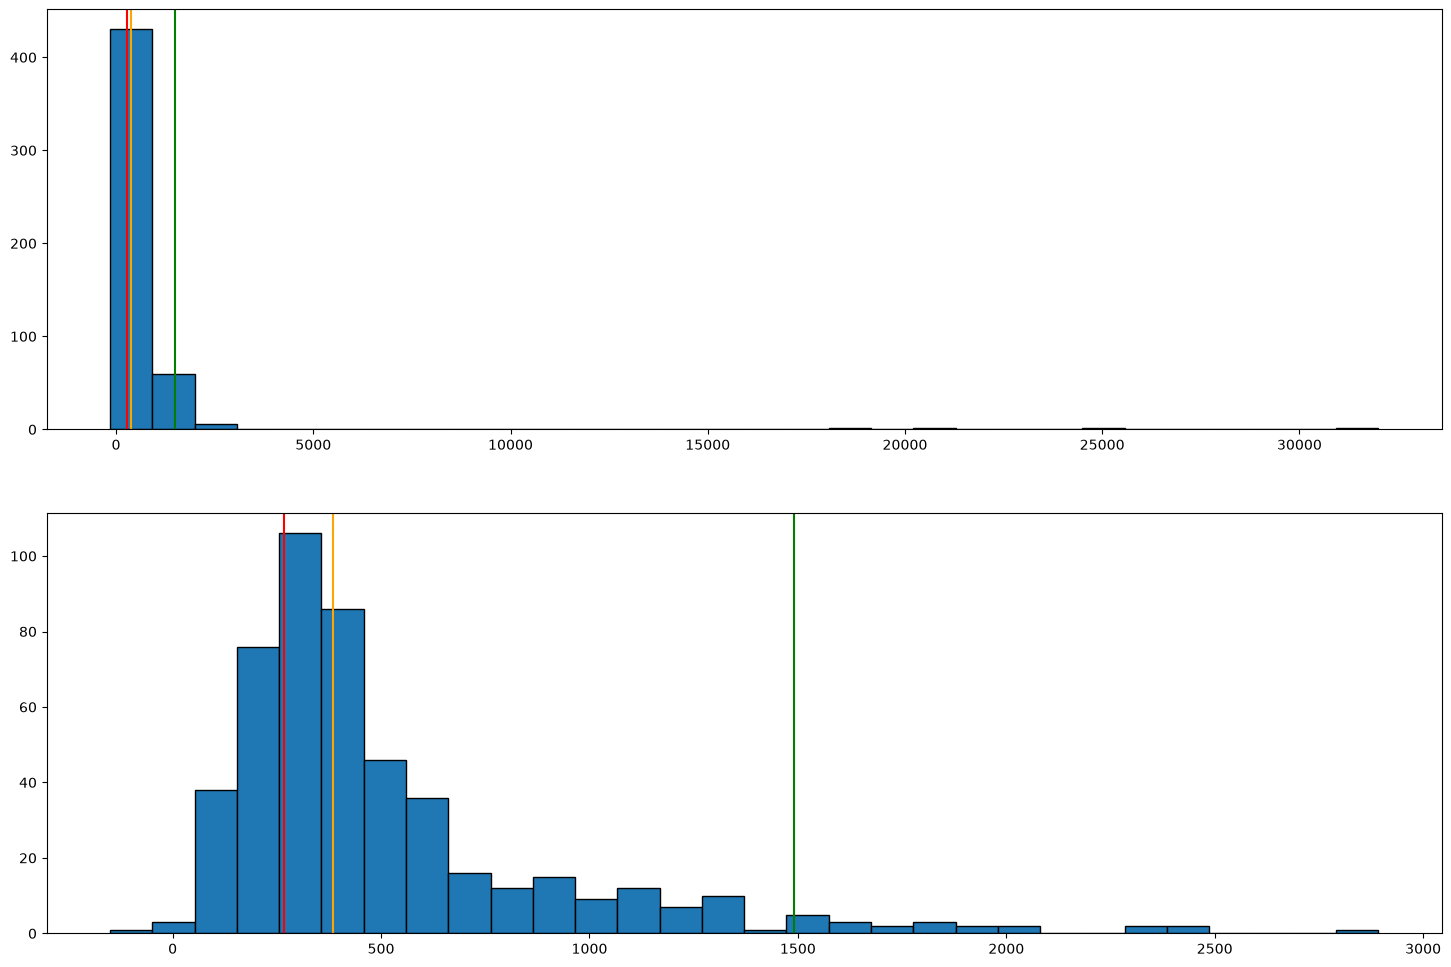

In [169]:
fig, axes = plt.subplots(2,1 ,figsize=(18, 12))
q1 = df['montant_dh'].quantile(0.25)
d5 = df['montant_dh'].quantile(0.50)
c95 = df['montant_dh'].quantile(0.95)


axes[0].hist(df['montant_dh'] ,bins = 30 ,edgecolor="black")
axes[0].axvline(q1 , color = 'red')
axes[0].axvline(d5, color = 'orange')
axes[0].axvline(c95 , color = 'green')


axes[1].hist(df.loc[df['montant_dh'] < 3000, 'montant_dh'] , bins= 30 , edgecolor = 'black')
axes[1].axvline(q1 , color = 'red')
axes[1].axvline(d5, color = 'orange')
axes[1].axvline(c95 , color = 'green')
plt.show()


In [170]:
for i in valeurs_num :
    print(f'les 5 grands valeurs dans {i} est : {df[i].nlargest(5)}')
    print(f'les 5 petits valeurs dans {i} est : {df[i].nsmallest(5)}')
    print('-' * 50)

les 5 grands valeurs dans age_client est : 31     130.0
213    118.0
371     62.0
482     61.0
281     60.0
Name: age_client, dtype: float64
les 5 petits valeurs dans age_client est : 380     0.0
203     5.0
3      18.0
16     18.0
35     18.0
Name: age_client, dtype: float64
--------------------------------------------------
les 5 grands valeurs dans nb_articles est : 115    40.0
146    35.0
4       7.0
116     7.0
271     7.0
Name: nb_articles, dtype: float64
les 5 petits valeurs dans nb_articles est : 178    0.0
5      1.0
12     1.0
13     1.0
16     1.0
Name: nb_articles, dtype: float64
--------------------------------------------------
les 5 grands valeurs dans montant_dh est : 110    32000.00
392    25000.00
409    21000.00
211    18500.00
334     2892.47
Name: montant_dh, dtype: float64
les 5 petits valeurs dans montant_dh est : 254   -150.00
144      0.50
213     15.00
91      48.00
260     54.23
Name: montant_dh, dtype: float64
------------------------------------------------

In [171]:
moyenne = df['montant_dh'].mean()
ecart = df['montant_dh'].std()
bas = moyenne - 2 * ecart
haut = moyenne + 2 * ecart

masque = (df['montant_dh'] < bas) | (df['montant_dh'] > haut)

print("Nombre détecté :", masque.sum(), '\n')
print(df.loc[masque, ['id_commande', 'montant_dh']])


Nombre détecté : 4 

    id_commande  montant_dh
110     CMD0109     32000.0
211     CMD0207     18500.0
392     CMD0383     25000.0
409     CMD0399     21000.0


In [172]:
moyenne = df['age_client'].mean()
ecart = df['age_client'].std()
bas = moyenne - 2 * ecart
haut = moyenne + 2 * ecart

masque = (df['age_client'] < bas) | (df['age_client'] > haut)

print("Nombre détecté :", masque.sum(), '\n')
print(df.loc[masque, ['id_commande', 'age_client']])


Nombre détecté : 10 

    id_commande  age_client
31      CMD0031       130.0
203     CMD0199         5.0
213     CMD0209       118.0
216     CMD0212        58.0
281     CMD0274        60.0
371     CMD0362        62.0
380     CMD0371         0.0
428     CMD0417        59.0
435     CMD0424        58.0
482     CMD0468        61.0


# Partie 5 — Détection et traitement des outli


In [173]:
for i in ["age_client", "nb_articles", "montant_dh", "delai_livraison_jours"] :
    q1, q3 = df[i].quantile([0.25, 0.75])
    iqr = q3 - q1
    masque = (df[i] < q1 - 1.5 * iqr) | (df[i] > q3 + 1.5 * iqr)
    print('Avec 1,5 :' )
    print(f"Pour {i} , Q1 = {q1} , Q3 = {q3} , IQR = {iqr} |||| les nombres des outliers est {masque.sum()}  \n" )
    masque = (df[i] < q1 - 3 * iqr) | (df[i] > q3 + 3 * iqr)
    print('Avec 3 :' )
    print(f"Pour {i} , Q1 = {q1} , Q3 = {q3} , IQR = {iqr} |||| les nombres des outliers est {masque.sum()}  \n" )
    
    

Avec 1,5 :
Pour age_client , Q1 = 27.0 , Q3 = 42.0 , IQR = 15.0 |||| les nombres des outliers est 3  

Avec 3 :
Pour age_client , Q1 = 27.0 , Q3 = 42.0 , IQR = 15.0 |||| les nombres des outliers est 2  

Avec 1,5 :
Pour nb_articles , Q1 = 1.0 , Q3 = 3.0 , IQR = 2.0 |||| les nombres des outliers est 8  

Avec 3 :
Pour nb_articles , Q1 = 1.0 , Q3 = 3.0 , IQR = 2.0 |||| les nombres des outliers est 2  

Avec 1,5 :
Pour montant_dh , Q1 = 266.0425 , Q3 = 609.7475 , IQR = 343.7049999999999 |||| les nombres des outliers est 47  

Avec 3 :
Pour montant_dh , Q1 = 266.0425 , Q3 = 609.7475 , IQR = 343.7049999999999 |||| les nombres des outliers est 19  

Avec 1,5 :
Pour delai_livraison_jours , Q1 = 2.0 , Q3 = 4.0 , IQR = 2.0 |||| les nombres des outliers est 4  

Avec 3 :
Pour delai_livraison_jours , Q1 = 2.0 , Q3 = 4.0 , IQR = 2.0 |||| les nombres des outliers est 3  



In [174]:
man_cat =  df.groupby('categorie')['montant_dh'].median()

<Axes: title={'center': 'montant_dh'}, xlabel='categorie'>

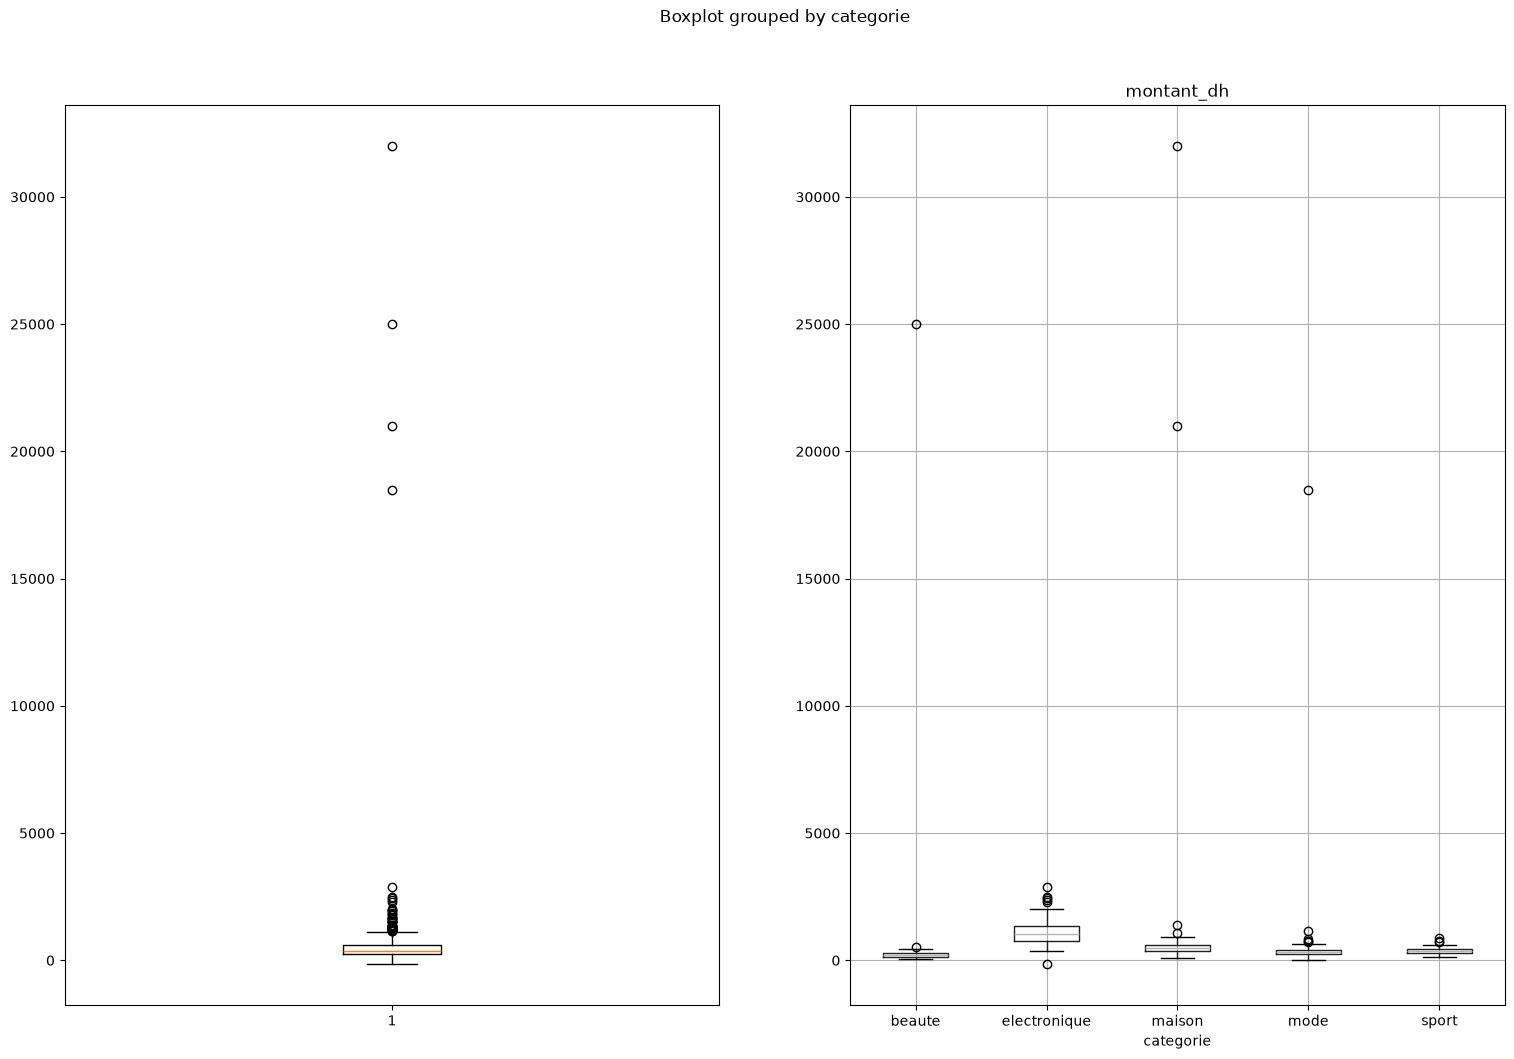

In [175]:

fig, axes = plt.subplots(1,2 ,figsize=(18, 12))
axes[0].boxplot(df['montant_dh'])
df.boxplot(column= 'montant_dh' ,  by = 'categorie' , ax = axes[1])


In [176]:
ecart_montant = np.std(df['montant_dh'])
moyenne_montant = np.mean(df['montant_dh'])
z_score_list = []
for i in df['montant_dh']:
    z_score = (i - moyenne_montant) / ecart_montant
    z_score_list.append(z_score)
df['z_montant'] = z_score_list

In [177]:
ecart_montant = np.std(df['age_client'])
moyenne_montant = np.mean(df['age_client'])
z_score_list = []
for i in df['age_client']:
    z_score = (i - moyenne_montant) / ecart_montant
    z_score_list.append(z_score)
df['z_age'] = z_score_list

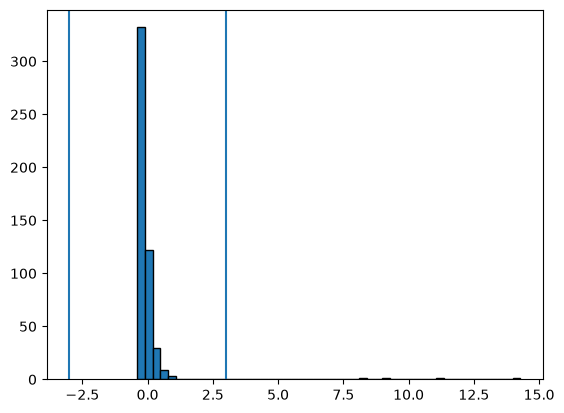

In [178]:
plt.hist(df['z_montant'], bins=50, edgecolor='black')
plt.axvline(x = 3)
plt.axvline(x = -3)


In [179]:
print("Methode de IQR (1,5) :")
i = 'montant_dh'
q1, q3 = df[i].quantile([0.25, 0.75])
iqr = q3 - q1
masque = (df[i] < q1 - 1.5 * iqr) | (df[i] > q3 + 1.5 * iqr)
print(f"le seuil est :({q1 - 1.5 * iqr} ; {q3 + 1.5 * iqr}) ")
print(i, masque.sum(), "outliers")
print('-' * 59)
print("Methode de IQR (3) :")
i = 'montant_dh'
q1, q3 = df[i].quantile([0.25, 0.75])
iqr = q3 - q1
masque = (df[i] < q1 - 3* iqr) | (df[i] > q3 + 3 * iqr)
print(f"le seuil est :({q1 - 3 * iqr} ; {q3 + 3 * iqr}) ")
print(i, masque.sum(), "outliers")
print('-' * 59)
print("Methode des deux ecart types :")
ecart = np.std(df['montant_dh'])
moyenne = np.mean(df['montant_dh'])
masque = (df['montant_dh'] < moyenne - 2 * ecart ) | (df['montant_dh'] >  moyenne + 2 * ecart)
print(f"seuil est : ({moyenne - 2 * ecart} ; {moyenne + 2 * ecart})")
print(masque.sum(), "outliers")
print('-' * 59)
print('methode de z_score :')
ecart_montant = np.std(df['montant_dh'])
moyenne_montant = np.mean(df['montant_dh'])
z_scores = (df['montant_dh'] - moyenne_montant) / ecart_montant
z_score_outlier = (np.abs(z_scores) > 3).sum()
print("le seuil est (-3 ; 3)")
print(f"{z_score_outlier} outlier")


Methode de IQR (1,5) :
le seuil est :(-249.51499999999987 ; 1125.3049999999998) 
montant_dh 47 outliers
-----------------------------------------------------------
Methode de IQR (3) :
le seuil est :(-765.0724999999998 ; 1640.8624999999997) 
montant_dh 19 outliers
-----------------------------------------------------------
Methode des deux ecart types :
seuil est : (-3684.0995608770127 ; 5086.154120877013)
4 outliers
-----------------------------------------------------------
methode de z_score :
le seuil est (-3 ; 3)
4 outlier


In [180]:
df.describe()

,date_commande,age_client,nb_articles,montant_dh,delai_livraison_jours,mois,z_montant,z_age
count,500,500.000000,500.000000,500.000000,500.000000,500.000000,5.000000e+02,5.000000e+02
mean,2025-07-02 15:07:12,34.944000,2.516000,701.027280,3.518000,6.550000,8.881784e-18,-2.309264e-16
min,2025-01-01 00:00:00,0.000000,0.000000,-150.000000,-2.000000,1.000000,-3.881426e-01,-3.061392e+00
25%,2025-04-01 18:00:00,27.000000,1.000000,266.042500,2.000000,4.000000,-1.983910e-01,-6.959621e-01
50%,2025-07-04 00:00:00,35.000000,2.000000,385.870000,3.000000,7.000000,-1.437392e-01,4.906077e-03
75%,2025-09-29 00:00:00,42.000000,3.000000,609.747500,4.000000,9.000000,-4.163153e-02,6.181657e-01
max,2025-12-30 00:00:00,130.000000,40.000000,32000.000000,60.000000,12.000000,1.427506e+01,8.327716e+00
std,NaN,11.425846,2.605248,2194.759278,3.765905,3.422122,1.001002e+00,1.001002e+00


In [181]:
valeurs_impossible  = df[(df['age_client'] <= 5) | (df['age_client'] >= 100) | (df['montant_dh'] < 0) | 
    (df['delai_livraison_jours'] < 0) | 
    (df['nb_articles'] == 0)
]
valeurs_impossible

,id_commande,date_commande,ville,sexe,age_client,categorie,canal,nb_articles,montant_dh,entrepot,delai_livraison_jours,colis_endommage,satisfaction,retour_client,mois,z_montant,z_age
31,CMD0031,2025-01-22,casablanca,femme,130.0,beaute,web,3.0,116.13,a,4.0,non,moyen,non,1,-0.266764,8.327716
178,CMD0175,2025-05-12,agadir,homme,27.0,mode,application,0.0,398.69,b,6.0,non,faible,non,5,-0.137892,-0.695962
203,CMD0199,2025-05-30,rabat,femme,5.0,maison,web,2.0,475.35,a,3.0,non,moyen,non,5,-0.102929,-2.623350
213,CMD0209,2025-06-06,fes,homme,118.0,mode,web,1.0,15.00,b,3.0,non,moyen,non,6,-0.312888,7.276413
254,CMD0248,2025-07-01,casablanca,femme,28.0,electronique,web,3.0,-150.00,b,2.0,non,eleve,non,7,-0.388143,-0.608354
358,CMD0349,2025-09-14,casablanca,homme,54.0,beaute,web,4.0,322.79,b,-2.0,non,faible,non,9,-0.172509,1.669468
380,CMD0371,2025-09-28,rabat,femme,0.0,beaute,telephone,1.0,178.88,c,4.0,non,faible,non,9,-0.238145,-3.061392


In [187]:
col = ['age_client' ,'montant_dh', 'delai_livraison_jours', 'nb_articles']

In [190]:
for i in col :
        median = df[i].median()
        if i == 'age_client':
                impossible = (df[i] <= 5) | (df[i] >= 100)
        elif i == 'montant_dh':
                impossible = (df['montant_dh'] < 0)
        elif i == 'delai_livraison_jours':
                        impossible = df['delai_livraison_jours'] < 0
        elif i == 'nb_articles':
                        impossible = df['nb_articles'] == 0
        df.loc[impossible , i] = np.nan
        df[i] = df[i].fillna(median)

In [191]:
df.describe()

,date_commande,age_client,nb_articles,montant_dh,delai_livraison_jours,mois,z_montant,z_age
count,500,500.000000,500.000000,500.000000,500.000000,500.000000,5.000000e+02,5.000000e+02
mean,2025-07-02 15:07:12,34.718000,2.520000,702.099020,3.528000,6.550000,8.881784e-18,-2.309264e-16
min,2025-01-01 00:00:00,18.000000,1.000000,0.500000,1.000000,1.000000,-3.881426e-01,-3.061392e+00
25%,2025-04-01 18:00:00,27.000000,1.000000,267.140000,2.000000,4.000000,-1.983910e-01,-6.959621e-01
50%,2025-07-04 00:00:00,35.000000,2.000000,385.870000,3.000000,7.000000,-1.437392e-01,4.906077e-03
75%,2025-09-29 00:00:00,41.000000,3.000000,609.747500,4.000000,9.000000,-4.163153e-02,6.181657e-01
max,2025-12-30 00:00:00,62.000000,40.000000,32000.000000,60.000000,12.000000,1.427506e+01,8.327716e+00
std,NaN,9.712009,2.602912,2194.473692,3.757853,3.422122,1.001002e+00,1.001002e+00


In [ ]:
df.to_csv("commandes_nettoye.csv", index=False)